# 6. Does a different team's pipeline see the same sectors deviate?

TARS is one team's way of turning TESS images into brightness curves. If our wander were an artefact of *their* detrending, a second team's curves of the same sectors would not show the same sector-to-sector deviations. The MIT Quick-Look Pipeline (QLP) publishes independent curves of the same images.

For 20 of our stars we take the QLP `SAP_FLUX` (the un-flattened flux — QLP's flattened flux removes rotation on purpose), remove a quadratic trend per TESS orbit, clip 5σ outliers, fit the identical single wave per sector, and compare each sector's deviation from the star's median angular speed between the two pipelines. The full pipeline did this for 60 stars and 660 sectors (Spearman ρ = 0.60); this is a 20-star version.

In [1]:
import sys; sys.path.insert(0, "..")
import json, time, os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import helpers as h
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
from astropy.io import fits
from scipy import stats

def load_qlp_sector(path):
    """QLP SAP flux, quality-filtered, quadratic trend removed per orbit, 5-sigma clipped."""
    with fits.open(path, memmap=False) as hdus:
        sector = int(hdus[0].header["SECTOR"]); d = hdus[1].data
        time = np.asarray(d["TIME"], float); flux = np.asarray(d["SAP_FLUX"], float)
        quality = np.asarray(d["QUALITY"], int); orbit = np.asarray(d["ORBITID"], int)
    keep = np.isfinite(time) & np.isfinite(flux) & (quality == 0) & (flux > 0)
    time, flux, orbit = time[keep], flux[keep], orbit[keep]
    if len(time) < h.MINIMUM_POINTS: return None
    norm = np.empty_like(flux)
    for o in np.unique(orbit):
        mask = orbit == o
        if mask.sum() < 50: norm[mask] = flux[mask] / np.median(flux[mask]); continue
        x = time[mask] - time[mask].mean(); norm[mask] = flux[mask] / np.polyval(np.polyfit(x, flux[mask], 2), x)
    resid = norm - np.median(norm); sigma = 1.4826 * np.median(np.abs(resid))
    keep = np.abs(resid) < 5 * max(sigma, 1e-6)
    time, flux = time[keep], norm[keep]
    if len(time) < h.MINIMUM_POINTS: return None
    noise = 1.4826 * np.median(np.abs(np.diff(flux))) / np.sqrt(2)
    return sector, time, flux, max(noise, 1e-5)

qlp_cache = h.DATA / "lightcurves" / "qlp"
qlp_files = sorted(qlp_cache.glob("*_llc.fits"))
print(len(qlp_files), "QLP sector files on disk")

660 QLP sector files on disk


In [3]:
from astroquery.mast import Observations
def download_qlp(tic_id, folder):
    folder = Path(folder); folder.mkdir(parents=True, exist_ok=True)
    obs = Observations.query_criteria(provenance_name="QLP", target_name=str(tic_id))
    if len(obs) == 0: return []
    products = Observations.get_product_list(obs)
    products = products[[str(f).endswith("_llc.fits") for f in products["productFilename"]]]
    manifest = Observations.download_products(products, download_dir=str(folder), cache=True)
    paths = []
    for local in manifest["Local Path"]:
        src = Path(local); dst = folder / src.name
        if src.exists() and not dst.exists(): src.replace(dst)
        paths.append(dst)
    return paths

# Pick 20 stars spread over temperature among those whose QLP files are already on disk (download otherwise).
stars = pd.read_csv("../results/stars_original.csv")
have = {int(p.name.split("-")[1].split("_")[0]) for p in qlp_files}
candidates = stars[stars.tic_id.isin(have)].sort_values("teff")
if len(candidates) < 20:
    for tic in stars.sort_values("teff").tic_id[:: max(1, len(stars) // 20)][:20]:
        try: download_qlp(int(tic), qlp_cache)
        except Exception as exc: print("could not download", tic, type(exc).__name__)
    qlp_files = sorted(qlp_cache.glob("*_llc.fits")); have = {int(p.name.split("-")[1].split("_")[0]) for p in qlp_files}
    candidates = stars[stars.tic_id.isin(have)].sort_values("teff")
chosen = candidates.iloc[np.linspace(0, len(candidates) - 1, 20).round().astype(int)]
print(len(chosen), "stars, temperatures", int(chosen.teff.min()), "to", int(chosen.teff.max()), "K")

20 stars, temperatures 3122 to 5875 K


In [4]:
lists = {r["tic_id"]: r for r in h.read_star_list("original_450")}
rows = []
for _, star in chosen.iterrows():
    tic = int(star.tic_id); p0 = lists[tic]["period"]
    tars = {int(k): 2 * np.pi / float(v) for k, v in (item.split(":") for item in star.sector_periods.split(","))}
    qlp = {}
    for path in qlp_cache.glob(f"*-{tic:016d}_*_llc.fits"):
        loaded = load_qlp_sector(path)
        if loaded is None: continue
        sector, t, f, noise = loaded
        if sector not in tars: continue
        fitted = h.fit_period(t, f, noise, p0)
        if fitted: qlp[sector] = 2 * np.pi / fitted[0]
    shared = sorted(set(tars) & set(qlp))
    if len(shared) < 5: continue
    d_tars = np.array([tars[s] for s in shared]); d_tars -= np.median(d_tars)
    d_qlp = np.array([qlp[s] for s in shared]); d_qlp -= np.median(d_qlp)
    rho = stats.spearmanr(d_tars, d_qlp).statistic
    for s, a, b in zip(shared, d_tars, d_qlp):
        rows.append(dict(tic_id=tic, teff=star.teff, sector=s, dev_tars=a, dev_qlp=b, star_rho=rho))
dev = pd.DataFrame(rows)
per_star = dev.groupby("tic_id").agg(teff=("teff", "first"), sectors=("sector", "size"), rho=("star_rho", "first"))
pooled = stats.spearmanr(dev.dev_tars, dev.dev_qlp)
print(f"{len(per_star)} stars, {len(dev)} shared sectors; pooled Spearman rho = {pooled.statistic:.2f} (p = {pooled.pvalue:.1e}); "
      f"{100*(per_star.rho > 0).mean():.0f}% of stars positive; median per-star rho = {per_star.rho.median():.2f}")
dev.to_csv("../results/qlp_sector_deviations.csv", index=False)

20 stars, 208 shared sectors; pooled Spearman rho = 0.62 (p = 1.2e-23); 100% of stars positive; median per-star rho = 0.61


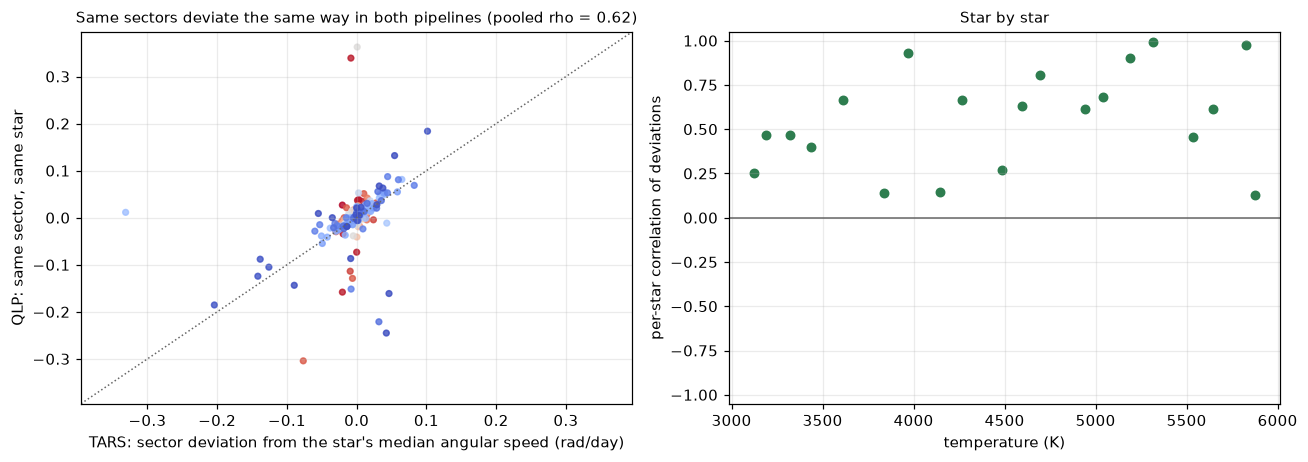

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
lim = np.nanpercentile(np.abs(np.r_[dev.dev_tars, dev.dev_qlp]), 99) * 1.1
axes[0].scatter(dev.dev_tars, dev.dev_qlp, s=14, c=dev.teff, cmap="coolwarm_r", alpha=0.8)
axes[0].plot([-lim, lim], [-lim, lim], color="0.4", lw=1, ls=":")
axes[0].set_xlim(-lim, lim); axes[0].set_ylim(-lim, lim)
axes[0].set_xlabel("TARS: sector deviation from the star's median angular speed (rad/day)"); axes[0].set_ylabel("QLP: same sector, same star")
axes[0].set_title(f"Same sectors deviate the same way in both pipelines (pooled rho = {pooled.statistic:.2f})", fontsize=10); axes[0].grid(alpha=0.25)
axes[1].scatter(per_star.teff, per_star.rho, s=30, color="#2e7d4f"); axes[1].axhline(0, color="0.4", lw=1)
axes[1].set_ylim(-1.05, 1.05); axes[1].set_xlabel("temperature (K)"); axes[1].set_ylabel("per-star correlation of deviations")
axes[1].set_title("Star by star", fontsize=10); axes[1].grid(alpha=0.25)
fig.tight_layout(); fig.savefig("../figures/06_qlp.png", dpi=150)

**Reading it.** Noise from the measurement process would be different in two independent reductions and would not correlate. The deviations correlate. The wander is on the star, not in the software. (Full pipeline, 60 stars / 660 sectors: ρ = 0.60, 98% of stars positive.)